In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rink import plot_rink

#векторный формат рисунков
%config InlineBackend.figure_formats = ['svg']

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'Liberation Serif']
plt.rcParams['font.size'] = 14

#три знака после запятой, как в подсказках
pd.set_option('display.float_format', '{:.3f}'.format)

## 1)

Чтение таблицы, делааем 1 колонку индексом index_col = 0, тогда остаётся тоже 38 полей

In [10]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col = 0)

print(events.shape)

events.iloc[:10, [2, 3, 4, 9, 12]]

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


## 2)

- Группируем события по Game ID
- Дата игры и названия команд одинаковы, поэтому можно взять первое значение из строки first
- Поля Cumulated Away Score и Cumulated Home Score увеличиваются, поэтому берём max
- Число овертаймов можно получить из номера последнего периода. Если больше 3 периодов, то уже овертайм, если 4 - то был один, если пять - то было два и тп. По гуглу овертаймов бесконечное количество в НХЛ, поэтому это тоже предусматриваем, можно сразу упростить для общего вида, как в коде
- Плюс переименовываем и убираем колонки, как в примере пункта 2

In [11]:
games = events.groupby('Game ID').agg({'Date': 'first',
                                       'Away Team': 'first',
                                       'Home Team': 'first',
                                       'Cumulated Away Score': 'max',
                                       'Cumulated Home Score': 'max',
                                       'Period': 'max'})

games = games.rename(columns={'Cumulated Away Score': 'Away Score',
                              'Cumulated Home Score': 'Home Score'})

#исход матча по номеру макс периода
def outcome(period):
    if period == 3:
        return 'Final'
    elif period == 4:
        return 'Final/OT'
    else:
        return 'Final/' + str(period - 3) + 'OT'

games['Outcome'] = games['Period'].apply(outcome)

games = games.drop(columns='Period')

print(games.columns)

games.iloc[-5:, -4:]

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')


,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


Получилась таблица из 82 игр

## 3)

- Числа переводятся в строки через str()

In [12]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return (game['Home Team'] + ' - ' + game['Away Team'] + ' ('
            + str(game['Home Score']) + ' - ' + str(game['Away Score']) + ', '
            + game['Outcome'] + ', ' + game['Date'] + ')')

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4)

- Складываем голы гостей и хозяев и смотрим описательные статистики

In [13]:
games['Total Score'] = games['Away Score'] + games['Home Score']

games['Total Score'].describe()

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64

- В среднем за матч забивают почти 6 шайб, медиана
- Минимум 1, максимум 15
- Нулевого счёта тоже нет: в плей-офф ничьих не бывает, овертаймы играют до гола,
поэтому хотя бы одна шайба в матче всегда есть

## 5)

- Всё по примеру seaborn.countplot() и подписи

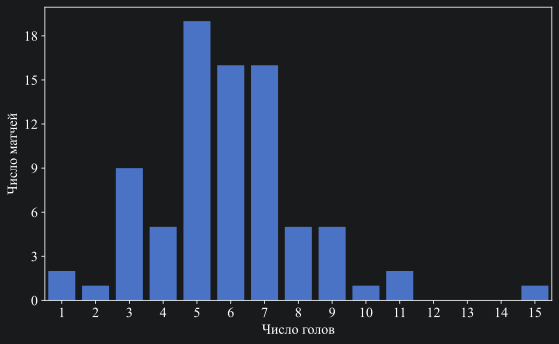

In [14]:
plt.figure(figsize=(8, 5))
sns.countplot(data=games, x='Total Score', order=range(1, 16))
plt.yticks(range(0, 19, 3))#ось ординат так же, как в пункте 5 через 3
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.tight_layout()
plt.show()

- Чаще всего в матче забивают 5 голов, дальше идут 6 и 7 голов,
то есть больше половины всех игр закончились с 5-7 голами в сумме

- Справа есть длинный хвост из редких результативных матчей 10, 11 и даже 15 голов.
Матчей с 12-14 голами не было совсем

## 6)

- Нерезультативные это игры, где сумма голов равна минимуму (когда максимуму, наоборот, результативные)
- GameInfo для каждой игры

In [15]:
lowRes = games[games['Total Score'] == games['Total Score'].min()]
[gameInfo(g) for g in lowRes.index]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [16]:
highRes = games[games['Total Score'] == games['Total Score'].max()]
[gameInfo(g) for g in highRes.index]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

- Самые нерезультативные - это два матча 1:0
- Самый результативный - это Colorado Avalanche - Minnesota Wild 9:6, всего 15 шайб.

## 7)

- Игроки на льду записаны в 14 полях: по 6 полей на игроков каждой команды и по одному на вратаря.
- Собираем из них одну таблицу без пустых значения и повторов.
- Команду храним вместе с игроком на случай однофамильцев в разных командах. Тогда число строк для каждой игры это число разных игроков, которые выходили на лёд.

In [17]:
#названия 14 полей с игроками на льду
away_cols = []
home_cols = []

#список названий колонок и вратарь
for i in range(1, 7):
    away_cols.append("Away Team's Player on the Ice #" + str(i))
    home_cols.append("Home Team's Player on the Ice #" + str(i))

away_cols.append("Away Team's Goalie")
home_cols.append("Home Team's Goalie")

#таблица: игра/команда/игрок
parts = []
for col in away_cols:
    df = events[['Game ID', 'Away Team', col]]
    df.columns = ['Game ID', 'Team', 'Player']

    parts.append(df)

for col in home_cols:
    df = events[['Game ID', 'Home Team', col]]
    df.columns = ['Game ID', 'Team', 'Player']

    parts.append(df)

appearances = pd.concat(parts).dropna().drop_duplicates()

games['Player Count'] = appearances.groupby('Game ID').size() #сколько строк у каждой игры, то есть сколько разных людей выходило на лёд
games['Game Info'] = [gameInfo(g) for g in games.index]

games[games['Player Count'] == games['Player Count'].max()][['Game Info', 'Player Count']] #макс

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Больше всего игроков было в матче Montréal Canadiens - Buffalo Sabres (3:8) - 40 человек.
Не уверен, как примере получилось 41, возможно, было посчитано пустое знаниче Nan. Всего в команде 20 человек, 41 не может быть

## 8)

Берём броски типа shot-on-goal, goal и missed-shot. Для каждого броска пишем функцию, которая:

1. определяет, в какие ворота бросали. Если бросают хозяева (Team Making the Play = Home Team)
   и их ворота слева (Home Team's Defending Side = left), то бросают в правые ворота, X = 89;
   если ворота хозяев справа, X = -89. Для гостей наоборот;

2. считает расстояние до ближайшей точки створа: ворота занимают по y отрезок от −3 до 3,
   поэтому если бросок был напротив ворот, расстояние просто |x − X|, а если выше или ниже, то расстояние
   до ближайшей штанги.


In [18]:
def shot_length(row):
    #в какие ворота бросали
    if row['Team Making the Play'] == row['Home Team']:
        if row["Home Team's Defending Side"] == 'left':
            X = 89
        else:
            X = -89
    else:
        if row["Home Team's Defending Side"] == 'left':
            X = -89
        else:
            X = 89

    x = row['X Coordinate on the Ice Rink']
    y = row['Y Coordinate on the Ice Rink']

    #расстояние до ближайшей точки створа
    if y < -3:
        return np.sqrt((x - X)**2 + (y + 3)**2)
    elif y <= 3:
        return abs(x - X)
    else:
        return np.sqrt((x - X)**2 + (y - 3)**2)

shots = events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])
events.loc[shots, 'Shot Length'] = events[shots].apply(shot_length, axis=1)

events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Всего 7266 незаблокированных бросков

## 9)

- Делим броски на две группы: missed (мимо) и on goal (в створ + включая голы).
- Чтобы сравнивать именно распределения, в seaborn.displot() можно поставить stat = density
(высота столбика по доле) и common_norm=False (чьтобы каждую группа нормировать отдельно)

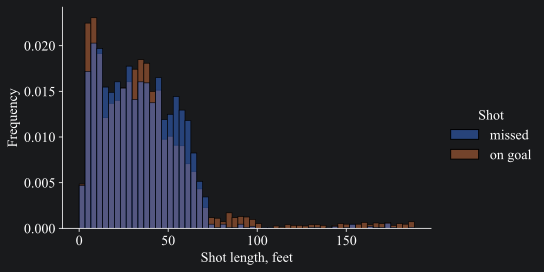

In [19]:
shots_df = events[shots].copy()
shots_df['Shot'] = np.where(shots_df['Play Type'] == 'missed-shot', 'missed', 'on goal') #делим на две группы, мимо missed, всё остальное on goal

g = sns.displot(data=shots_df, x='Shot Length', hue='Shot', stat='density', common_norm=False,
                height=4, aspect=1.6)

g.set_axis_labels('Shot length, feet', 'Frequency')
plt.show()

- В целом распределения похожи: большинство и точных, и неточных бросков делается с 5–65 футов от ворот,
у тех и других половина бросков ближе (примерно 32 футов). До 45 футов гистограммы почти совпадают,
а на 45–65 футов относительно больше неточных бросков (из-за дальности сложнее попасть)

- Дальше 75 футов неточных бросков почти нет, а у точных есть длинный хвост
вплоть до 190 футов, то есть бросков с собственной половины площадки.

- С учётом моего опыта в игру NHL 14 на XBOX360, предполагаю, что это голы в пустые ворота (если вратаря убрали) и выгодно бросить из своей половины поля и так называемые пробросы тоже со своей половины поля

## 10)

- Незаблокированные броски - это shot-on-goal, goal и missed-shot (пункт 8)
- Делаем колонку On Goal: True, если бросок в створ (или гол). Среднее от True/False будет как раз долей True,
поэтому группируем по игре и команде и берём .mean()

In [20]:
shots_df['On Goal'] = shots_df['Play Type'].isin(['shot-on-goal', 'goal'])

numshots = shots_df.groupby(['Game ID', 'Team Making the Play'])[['On Goal']].mean()

numshots.columns = ['Share of Shots on Goal']

numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins          0.625
            Buffalo Sabres         0.679
2025030112  Boston Bruins          0.614
            Buffalo Sabres         0.636
2025030113  Boston Bruins          0.694
                                    ... 
2025030414  Vegas Golden Knights   0.583
2025030415  Carolina Hurricanes    0.558
            Vegas Golden Knights   0.510
2025030416  Carolina Hurricanes    0.639
            Vegas Golden Knights   0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [21]:
numshots['Share of Shots on Goal'].describe()

count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: Share of Shots on Goal, dtype: float64

- Получилось 164 значения. По две команды в каждой из 82 игр. В среднем в створ попадает примерно
2 из 3 незаблокированных бросков (доля 0.64).
- Но от игры к игре доля сильно скачет: от 0.35 до 0.86

## 11)

Усредняем долю из пункта 10 по всем играм каждой команды.

In [22]:
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()

avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers       0.706
Philadelphia Flyers   0.684
Dallas Stars          0.670
Minnesota Wild        0.656
Colorado Avalanche    0.653
Name: Share of Shots on Goal, dtype: float64

In [23]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins   0.554
Utah Mammoth          0.599
Carolina Hurricanes   0.615
Tampa Bay Lightning   0.626
Buffalo Sabres        0.626
Name: Share of Shots on Goal, dtype: float64

- Самые точные: Edmonton Oilers (71% бросков в створ), Philadelphia Flyers и Dallas Stars,
самые неточные: Pittsburgh Penguins (55%), Utah Mammoth и Carolina Hurricanes.

- Разница между командами (0.55-0.71) намного меньше, чем разброс от игры к игре в пункте 10.



## 12)

- Броски в створ - это shot-on-goal вместе с голами (гол - это тоже бросок в створ).
- Считаем, сколько всего бросков в створ и голов у каждой команды, и делим на число сыгранных ею игр.
- Число игр берём из таблицы games (команда была либо гостем, либо хозяином), а не из событий: иначе игры,
где команда не забила ни одного гола, выпали бы из подсчёта голов.

In [24]:
#сколько игр сыграла каждая команда
n_games = pd.concat([games['Away Team'], games['Home Team']]).value_counts()

shots_on_goal = events[events['Play Type'].isin(['shot-on-goal', 'goal'])].groupby('Team Making the Play').size()

goals_total = events[events['Play Type'] == 'goal'].groupby('Team Making the Play').size()

avgshots = pd.DataFrame({'Shot': shots_on_goal / n_games,
                         'Goal': goals_total / n_games})

avgshots.index.name = 'Team Making the Play'

avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13)

- Рисуем seaborn.regplot()

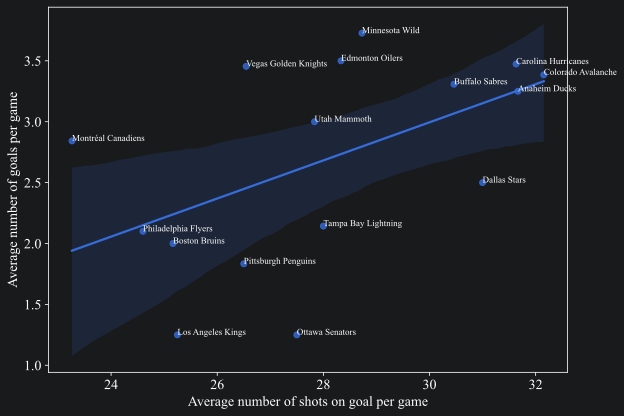

np.float64(0.5207961205304794)

In [25]:
plt.figure(figsize=(9, 6))
sns.regplot(data=avgshots, x='Shot', y='Goal')
for team in avgshots.index:
    plt.text(avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal'], team, fontsize=9)

plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.tight_layout()

plt.show()

#коэффициент корреляции
avgshots['Shot'].corr(avgshots['Goal'])

- Связь видна, но слабая. Линия идёт вверх: команды, которые больше бросают в створ (Colorado, Carolina,
Anaheim, Buffalo), в среднем и забивают больше. Корреляция около 0.52.
- Но есть и исключения: Dallas Stars бросает много (31 бросок за игру), а забивает всего 2.5 гола.
- Но точки сильно разбросаны вокруг линии, а полоса доверительного интервала широкая. Например,
Montréal Canadiens бросает меньше всех (23 броска), а забивает почти 3 гола за игру,
Ottawa Senators бросает средне, а забивает меньше всех (1.25, как и Los Angeles Kings).
- К тому же команд всего 16, и некоторые сыграли только 4–6 матчей. Так что число бросков объясняет
число голов лишь частично, многое зависит от качества бросков и игры вратарей.

## 14)

- Считаем все удары: в створ, голы, мимо и заблокированные. Группируем по играм, .idxmax() даёт номер игры
с максимумом.

In [26]:
all_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]

shots_per_game = all_shots.groupby('Game ID').size()

idxmax = shots_per_game.idxmax()

print(shots_per_game.max())

gameInfo(idxmax)

208


'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

## 15)

- Команды меняются воротами каждый период, поэтому в нечётных периодах переворачиваем координаты:
(x, y) (-x, -y). Тогда во всех периодах гости бьют в левые ворота, а хозяева в правые.

- Для этого матча правило из условия подходит: в чётных периодах ворота хозяев здесь слева
(Home Team's Defending Side = left), то есть хозяева бьют вправо.

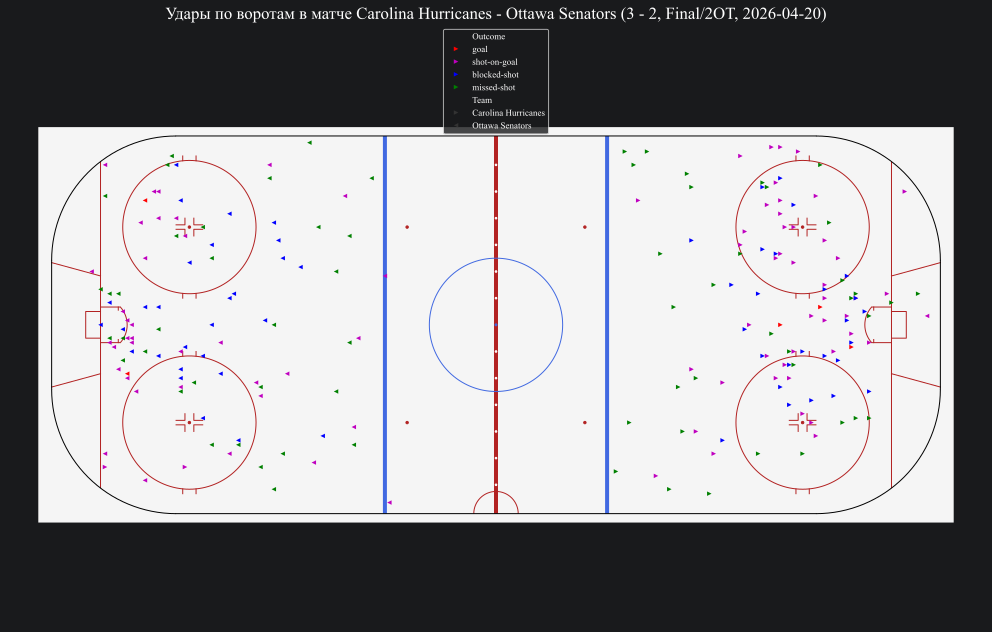

In [27]:
match = all_shots[all_shots['Game ID'] == idxmax].copy()
match['x'] = match['X Coordinate on the Ice Rink']
match['y'] = match['Y Coordinate on the Ice Rink']

#в нечетных периодах переворачиваем координаты
odd = match['Period'] % 2 == 1
match.loc[odd, 'x'] = -match.loc[odd, 'x']
match.loc[odd, 'y'] = -match.loc[odd, 'y']

match['Outcome'] = match['Play Type']
match['Team'] = match['Team Making the Play']

plt.figure(figsize=(14, 9))
plot_rink()
sns.scatterplot(data=match, x='x', y='y', hue='Outcome', style='Team',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette=['red', 'm', 'blue', 'green'],
                markers={'Carolina Hurricanes': '>', 'Ottawa Senators': '<'},
                s=20, linewidth=0)
plt.axis('equal')
plt.axis('off')

plt.legend(loc='upper center', fontsize=9)

plt.title('Удары по воротам в матче ' + gameInfo(idxmax))

plt.tight_layout()
plt.show()

## 16)

- Автор гола это Player in the Event #1 у событий goal.
- Считаем голы через value_counts(). Чтобы не обрезать игроков с одинаковым числом голов на последнем месте, берём nlargest(10, keep = all). Так в список попадут все, кто делит 10-е место.

In [28]:
goals = events[events['Play Type'] == 'goal']

goals['Player in the Event #1'].value_counts().nlargest(10, keep = 'all')

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Matt Boldy           7
Mark Stone           7
Name: count, dtype: int64

Больше всех забил Brett Howden (14 голов)

## 17)

- Голевые передачи это Player in the Event #2 (первый ассистент) и Player in the Event #3 (второй ассистент)
у событий goal. Ставим обе колонки друг под другом через pd.concat() и считаем.

In [29]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']])

assists.value_counts().nlargest(10, keep = 'all')

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

## 18)

- Очки - это голы и передачи вместе, поэтому склеиваем все три колонки игроков у голов.

In [30]:
points = pd.concat([goals['Player in the Event #1'],
                    goals['Player in the Event #2'],
                    goals['Player in the Event #3']])

points.value_counts().nlargest(10, keep = 'all')

Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Brett Howden       18
Shea Theodore      18
Nikolaj Ehlers     18
Lane Hutson        16
Nick Suzuki        16
Logan Stankoven    16
Pavel Dorofeyev    16
Name: count, dtype: int64

Больше всех очков у Mitch Marner (29)

## 19)

- Число бросков в створ (shot-on-goal и goal) у каждого игрока делим на число игр, в которых он выходил на лёд.
Число игр берём из таблицы appearances из пункта 7.

In [31]:
#в скольких играх игрок выходил на лёд
games_played = appearances.groupby('Player')['Game ID'].nunique()

player_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]['Player in the Event #1'].value_counts()

(player_shots / games_played).nlargest(10, keep = 'all')

Player in the Event #1
Jason Robertson    5.000
Dylan Guenther     4.500
Nikita Kucherov    4.429
Matt Boldy         4.364
Quinton Byfield    4.250
Darren Raddysh     4.000
Joel Eriksson Ek   4.000
Alex Laferriere    3.750
David Pastrnak     3.667
Nathan MacKinnon   3.615
dtype: float64

у многих лидеров мало игр, поэтому среднее посчитано по маленькому числу матчей

## 20)

- То же самое для событий hit: автор силового приёма - это Player in the Event #1.

In [32]:
player_hits = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()

(player_hits / games_played).nlargest(10, keep = 'all')

Player in the Event #1
Lawson Crouse        6.333
Alex Turcotte        6.000
Alexander Petrovic   6.000
Yakov Trenin         5.667
Dylan Cozens         5.500
Vasily Podkolzin     5.333
Carl Grundstrom      5.000
Ivan Barbashev       5.000
Marcus Foligno       5.000
Owen Tippett         4.833
dtype: float64

Lawson Crouse сигма

## 21)

- Для каждого гола находим вратаря, который его пропустил. Если забили хозяева, то пропустил вратарь гостей
(Away Team's Goalie), иначе вратарь хозяев.
- Потом для каждой пары "игра и вратарь"
(вратарь выходил на лёд в этой игре) считаем пропущенные голы и оставляем пары, где их 0.
Так можно учесть и вратарей, которые играли не весь матч.


В строке события goal записан состав на льду уже после гола, то есть он всегда совпадает
со следующим событием (то есть вбрасыванием после гола). Это хорошо видно на заменах: например, в матче Buffalo - Boston
вратарь Buffalo Luukkonen пропустил четыре гола и его заменили на Alex Lyon, но в строке четвёртого гола
уже стоит Lyon. Если брать вратаря прямо из строки гола, этот гол засчитался бы Lyon.
Поэтому вратарей на момент гола нужно брать из предыдущего события с помощью .shift(1), сдвигая таблицу на одну строку вниз.
Так в строке гола оказываются значения из строки перед ним (гол никогда не бывает первым событием матча,
так что предыдущая строка всегда из той же игры).

Заодно это решает вторую проблему: у всех 22 голов в овертаймах в строке гола состав вообще не записан
(0 игроков на льду), а в предыдущем событии он есть. Если в предыдущем событии вратаря на льду не было
(пустое значение), это гол был в пустые ворота и он никому не засчитывается

In [33]:
cols = ["Away Team's Goalie", "Home Team's Goalie"]

#в строке гола состав уже после гола. нужно брать вратарей из предыдущего события
prev = events[cols].shift(1)

goals2 = events[events['Play Type'] == 'goal'].copy()
goals2[cols] = prev.loc[goals2.index]

#кто пропустил каждый гол
goals2['Conceded By'] = np.where(goals2['Team Making the Play'] == goals2['Home Team'],
                                 goals2["Away Team's Goalie"], goals2["Home Team's Goalie"])
count = goals2.groupby(['Game ID', 'Conceded By']).size()

#все пары игра - команда - вратарь
tables = []
t = events[['Game ID', 'Away Team', "Away Team's Goalie"]]
t.columns = ['Game ID', 'Team', 'Goalie']

tables.append(t)

t = events[['Game ID', 'Home Team', "Home Team's Goalie"]]
t.columns = ['Game ID', 'Team', 'Goalie']

tables.append(t)

all_goalies = pd.concat(tables).dropna().drop_duplicates()

#сколько пропустил каждый вратарь в каждой игре
count = count.reset_index()

count.columns = ['Game ID', 'Goalie', 'Conceded']
all_goalies = pd.merge(all_goalies, count, on=['Game ID', 'Goalie'], how='left')
all_goalies['Conceded'] = all_goalies['Conceded'].fillna(0)

#сколько вратарей было у команды в игре: 1 - весь матч, 2 - была замена
all_goalies['Goalies'] = all_goalies.groupby(['Game ID', 'Team'])['Goalie'].transform('count')
all_goalies['Played'] = np.where(all_goalies['Goalies'] == 1, 'весь матч', 'замена')

#вратари без пропущенных голов
result = all_goalies[all_goalies['Conceded'] == 0]

result[['Goalie', 'Played']].drop_duplicates().sort_values(['Played', 'Goalie'], ascending=[False, True])

,Goalie,Played
88,Alex Lyon,замена
91,Joonas Korpisalo,замена
151,Scott Wedgewood,замена
52,Ukko-Pekka Luukkonen,замена
11,Andrei Vasilevskiy,весь матч
85,Brandon Bussi,весь матч
18,Dan Vladar,весь матч
73,Frederik Andersen,весь матч


Таких вратарей 8: четверо отыграли весь матч на ноль, четверо вышли на замену и не пропустили

## 22) Свой вопрос: часто ли побеждает команда, которая забила первой?

- Для каждой игры находим команду, забившую первый гол
(события внутри игры идут по порядку, поэтому это первый гол в группе .first()), и победителя матча.

In [34]:
first_goal = goals.groupby('Game ID')['Team Making the Play'].first()

games['First Goal'] = first_goal
games['Winner'] = np.where(games['Home Score'] > games['Away Score'], games['Home Team'], games['Away Team'])

#доля игр, в которых победила команда, забившая первой
print((games['First Goal'] == games['Winner']).mean())

#доля побед хозяев
print((games['Winner'] == games['Home Team']).mean())

0.6829268292682927
0.47560975609756095


- Команда, открывшая счёт, выиграла 68% матчей
- (Для сравнения, своя площадка в этом плей-офф преимущества не дала: хозяева выиграли даже меньше половины матчей (48%))
Получается, что забить первым гораздо важнее, чем играть дома